## Лабораторная работа №4
Задание:
1. Реализовать полносверточную нейронную сеть (полностью сверточную сеть, без полносвязных слоев) на библиотеке Keras (можно PyTorch, JAX, TensorFlow) для сегментации клеточных стенок.
Выборка медицинских изображений клеточных мембран ISBI 2012: (https://drive.google.com/drive/folders/1fLDfatKLTiay1KZOXb5F-MIY-0gPnbvI?usp=share_link).
Описание выборки: (https://imagej.net/events/isbi-2012-segmentation-challenge).
Так как тестовая выборка не дана, использовать 5 изображений из обучающей выборки в качестве тестовой выборки.
(PyTorch тоже можно использовать. Полностью свою реализацию тоже можно, но сможете ли ускорить? :/)

2. Самостоятельно разметить Одно изображение из тестовой выборки данных, выделив клеточные стенки на изображении и сравнить с полученным результатом нейронной сети (получится желаемый результат для нейронной сети и точность на нем, можно попробовать использовать в помощь обученную нейронную сеть и поправить ее ответ). Постарайтесь взять разные изображения из тестовой выборки, чтобы не пересекаться.
(Можно попробовать использовать: Paint (сложно и долго), Photoshop, Krita (бесплатный аналог Photoshop)).


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Path:<br>
train&nbsp;&nbsp;-&nbsp;&nbsp;"/content/drive/MyDrive/Клеточные мембраны/train"<br>
test&nbsp;&nbsp;&nbsp;-&nbsp;&nbsp;"/content/drive/MyDrive/Клеточные мембраны/test"

### Подготовка масок для разметки

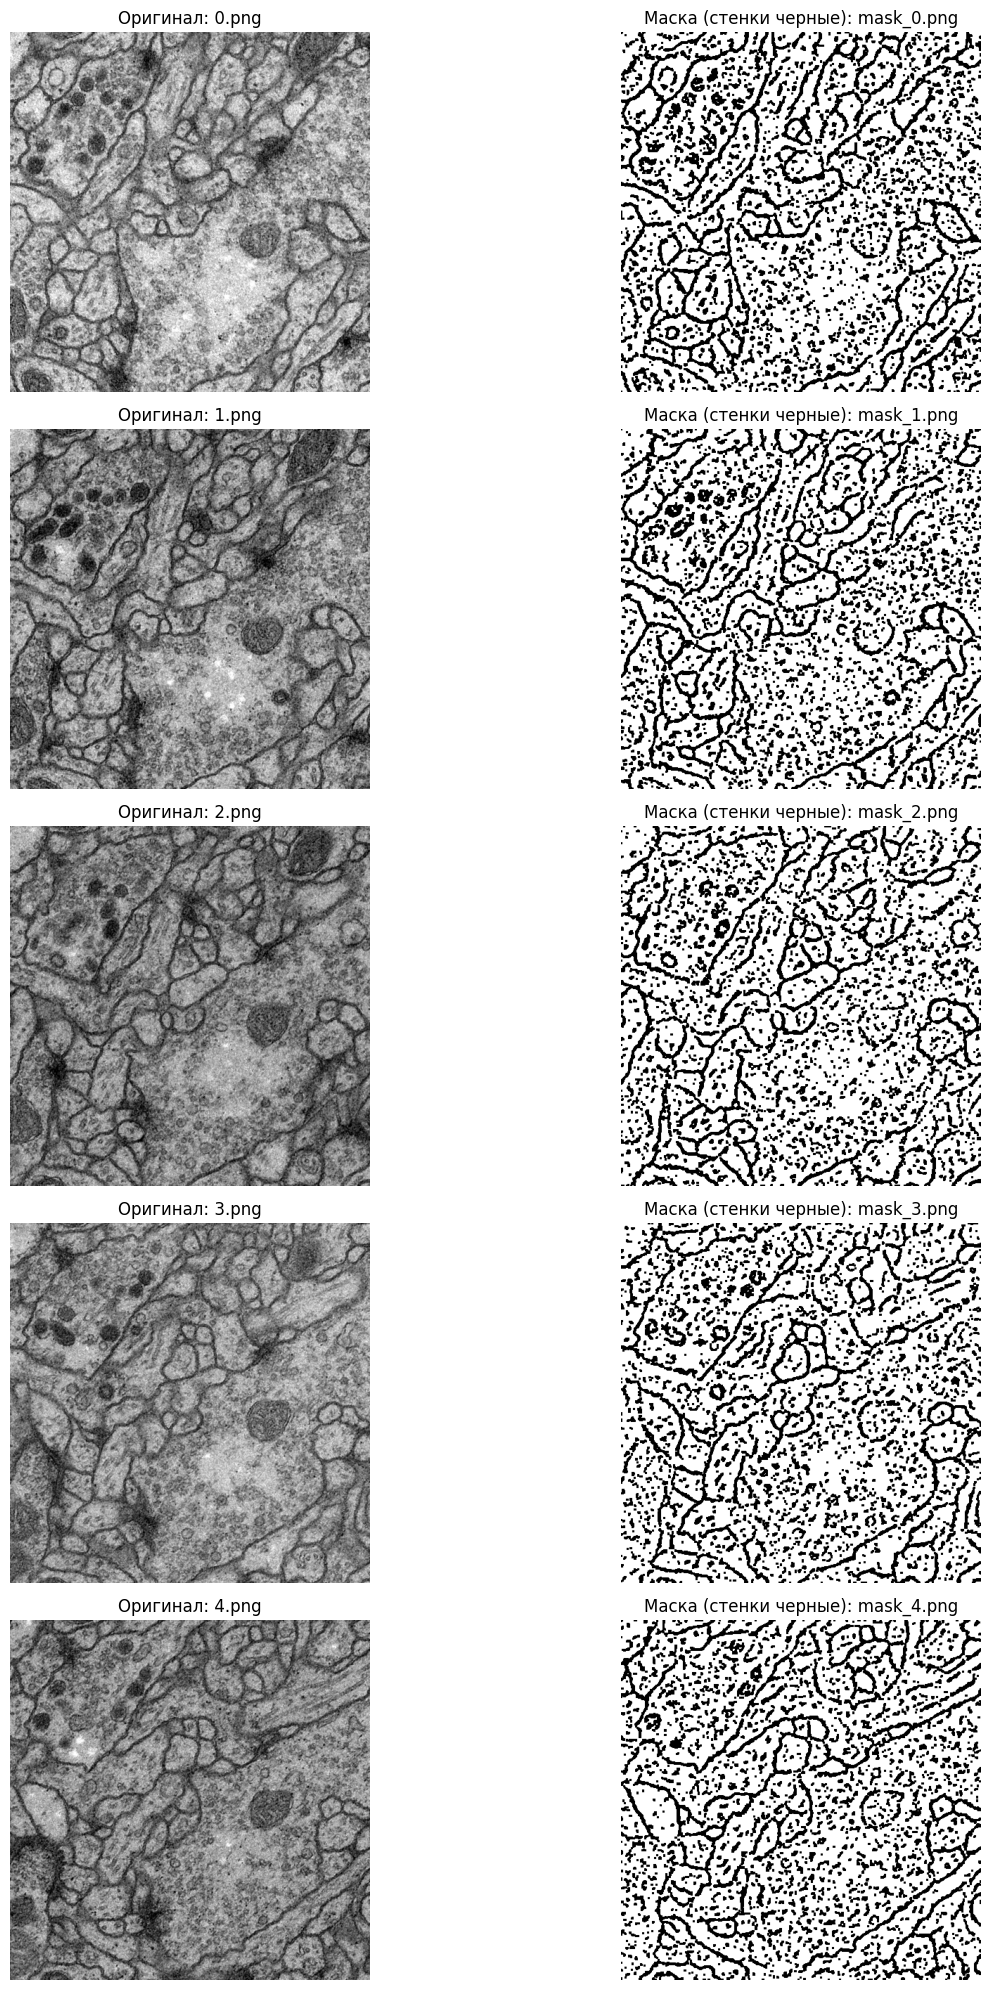

Правильные маски сохранены в: /content/drive/MyDrive/Клеточные мембраны/test/image/generated_masks


In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Укажите путь к вашей папке с 5 картинками
IMAGE_DIR = "/content/drive/MyDrive/Клеточные мембраны/test/image"

file_names = [
    '0.png',
    '1.png',
    '2.png',
    '3.png',
    '4.png'
]

mask_dir = os.path.join(IMAGE_DIR, 'generated_masks')
os.makedirs(mask_dir, exist_ok=True)

plt.figure(figsize=(15, 20))

for i, name in enumerate(file_names):
    img_path = os.path.join(IMAGE_DIR, name)

    if not os.path.exists(img_path):
        print(f"Файл {name} не найден!")
        continue

    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

    # Плавное размытие, чтобы убрать мелкий шум электронного микроскопа
    blurred = cv2.GaussianBlur(img, (5, 5), 0)

    # ИСПРАВЛЕНО: THRESH_BINARY вместо THRESH_BINARY_INV.
    # Теперь стенки будут ЧЕРНЫМИ, как в вашей обучающей выборке.
    mask = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY, blockSize=25, C=7
    )

    # Морфологическое сглаживание для удаления мелких черных точек внутри клеток
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    # Сохраняем готовую маску в правильном формате
    mask_name = f"mask_{name}"
    cv2.imwrite(os.path.join(mask_dir, mask_name), mask)

    # Отрисовка результатов
    plt.subplot(5, 2, 2*i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"Оригинал: {name}")
    plt.axis('off')

    plt.subplot(5, 2, 2*i + 2)
    plt.imshow(mask, cmap='gray')
    plt.title(f"Маска (стенки черные): {mask_name}")
    plt.axis('off')

plt.tight_layout()
plt.show()
print(f"Правильные маски сохранены в: {mask_dir}")


### Размеченная в Paint маска для изображения "3.png" из test

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]], dtype=uint8)
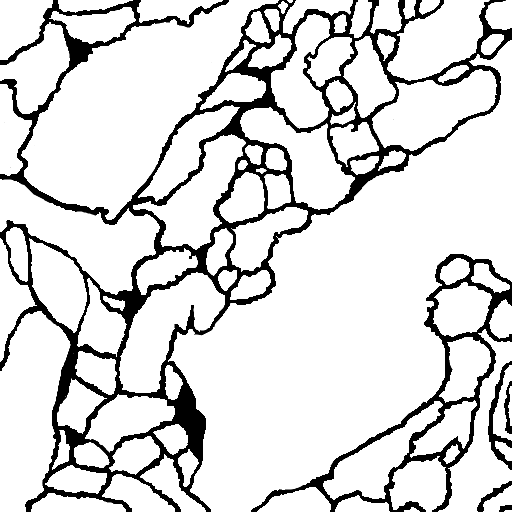

In [3]:
cv2.imread('/content/drive/MyDrive/Клеточные мембраны/test/mask/mask_3.png')

### Пайплайн

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision
import torchvision.transforms as T
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import os
from tqdm import tqdm

In [5]:
class CellSegmentationDataset(Dataset):
  def __init__(self, image_dir, mask_dir, transforms=None):
    self.image_dir = image_dir
    self.mask_dir = mask_dir
    self.transforms = transforms
    self.images = sorted(os.listdir(image_dir))
    self.masks = sorted(os.listdir(mask_dir))

  def __len__(self):
    return len(self.images)

  def __getitem__(self, idx):
    image_path = os.path.join(self.image_dir, self.images[idx])
    mask_path = os.path.join(self.mask_dir, self.masks[idx])
    image = Image.open(image_path).convert('L')
    mask = Image.open(mask_path).convert('L')
    image = T.ToTensor()(image)
    mask = T.ToTensor()(mask)
    return image, mask

In [20]:
class EarlyStopping(nn.Module):
  def __init__(self, patience=15, path='best_cell_model.pth'):
    self.patience = patience
    self.path = path
    self.counter = 0
    self.best_loss = float('inf')
    self.early_stop = False

  def __call__(self, val_loss, model):
    if val_loss < self.best_loss:
      self.best_loss = val_loss
      torch.save(model.state_dict(), self.path)
      self.counter = 0
    else:
      self.counter += 1
      if self.counter >= self.patience:
          self.early_stop = True

class ConvBlock(nn.Module):
  def __init__(self, in_ch, out_ch):
    super().__init__()
    self.block = nn.Sequential(
        nn.Conv2d(in_channels=in_ch, out_channels=out_ch, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.LeakyReLU(0.2, inplace=True)
    )

  def forward(self, x):
    return self.block(x)

class EncoderBlock(nn.Module):
  def __init__(self, in_ch, out_ch):
    super().__init__()
    self.conv = ConvBlock(in_ch, out_ch)
    self.down = nn.MaxPool2d(kernel_size=2, stride=2)

  def forward(self, x):
    skip = self.conv(x)
    x = self.down(skip)
    return x, skip

class DecoderBlock(nn.Module):
  def __init__(self, in_ch, out_ch):
    super().__init__()
    self.up = nn.Sequential(
        nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
        nn.Conv2d(in_ch, out_ch, kernel_size=1)
    )
    self.conv = ConvBlock(out_ch + out_ch, out_ch)

  def forward(self, x, skip):
    x = self.up(x)
    x = torch.cat([x, skip], dim=1)
    return self.conv(x)

class Attention(nn.Module):
  def __init__(self, in_ch):
    super().__init__()
    self.in_ch = in_ch
    self.query = nn.Linear(in_ch, in_ch)
    self.key = nn.Linear(in_ch, in_ch)
    self.value = nn.Linear(in_ch, in_ch)

  def forward(self, x):
    B, C, H, W = x.shape
    x_flatten = x.flatten(2)          # [B, C, H, W] -> [B, C, H*W]
    x_tokens = x_flatten.transpose(1, 2)      # [B, C, H*W]  -> [B, H*W, C] или [B, 32x32=1024, 128]

    Q = self.query(x_tokens)
    K = self.key(x_tokens)
    V = self.value(x_tokens)

    scores = Q @ K.transpose(1, 2)   # Матричное перемножение, которое даст нам карту интересов одних пикселей к другим
                                           # размера [B, 1024, 1024]
    scores = scores / (self.in_ch ** 0.5)  # Защита от ваниша
    attn_weights = torch.softmax(scores, dim=-1)  # Превращаем сырые числа на карте в вероятности (сумма строки = 1)
    attn_out = attn_weights @ V                   # Перемножаем карту на значения и получили "очищенные" признаки [B, 1024, 128]

    out = attn_out.transpose(1, 2)         # [B, H*W, C]  -> [B, C, H*W]
    out = out.reshape(B, C, H, W)          # [B, C, H*W]  -> [B, C, H, W]
    return x + out                   # Сложение исходника с выходом специально сделано, поскольку на старте обучения веса модели
                                     # инициализированы случайным образом, потому вывод одного лишь out мог бы стереть полезные
                                     # признаки, выведенные свертками. При такой реализации attention просто дописывает
                                     # полезную информацию, которую смог вывести

class CellModel(nn.Module):
  def __init__(self, in_ch=1, out_ch=1, use_attention=True):
    super().__init__()
    self.use_attention = use_attention
    self.encoder = nn.ModuleList([
        EncoderBlock(1, 16),    # 512x512 -> 256x256
        EncoderBlock(16, 32),   # 256x256 -> 128x128
        EncoderBlock(32, 64),   # 128x128 -> 64x64
        EncoderBlock(64, 128),  # 64x64 -> 32x32
    ])

    if self.use_attention:                        # Наглядное сравнение моделей с вниманием и без него
      self.bottleneck = nn.Sequential(
          Attention(128),
          ConvBlock(128, 128),
      )
    else:
      self.bottleneck = ConvBlock(128, 128)

    self.decoder = nn.ModuleList([
        DecoderBlock(128, 128), # 128 апсемплит в 128, а потом добавит скип: 128 + 128 = 256 -> 256 / 2 = 128
        DecoderBlock(128, 64),  # 128 в 64 -> 64 + 64 = 128 -> 128 / 2 = 64
        DecoderBlock(64, 32),
        DecoderBlock(32, 16),
    ])
    self.final = nn.Conv2d(16, out_ch, kernel_size=1)

  def forward(self, x):
    x, skip1 = self.encoder[0](x)
    x, skip2 = self.encoder[1](x)
    x, skip3 = self.encoder[2](x)
    x, skip4 = self.encoder[3](x)
    x = self.bottleneck(x)
    x = self.decoder[0](x, skip4)
    x = self.decoder[1](x, skip3)
    x = self.decoder[2](x, skip2)
    x = self.decoder[3](x, skip1)
    x = self.final(x)
    # Сигмоиду не добавляем, чтобы получить сырые логиты для BCEWithLogitsLoss
    return x

Для решения задачи была выбрана связка лоссов из BCEWithLogitsLoss и DiceLoss. Первый попиксельно сравнивает точность картинок, из-за чего у модели может появиться желание схитрить. Если на картинке 95% пустого пространства и 5% стенок, она может выдать белую картинку и получить низкий BCE. Именно от этой ситуации нас защищает DiceLoss. Он оценивает не отдельные пиксели, а схожесть геометрических форм и пересечение целевых областей. Если модель полностью проигнорирует и "сотрёт" клеточные стенки, DiceLoss выдаст максимальную ошибку (равную 1), что заставит сеть восстанавливать тонкую структуру мембран и непрерывность линий.

In [7]:
class DiceLoss(nn.Module):
  def __init__(self, smooth=1e-6):
    super().__init__()
    self.smooth = smooth                      # Защита от ZeroDivisionError

  def forward(self, pred_logits, targets):
    preds = torch.sigmoid(pred_logits)
    preds = preds.view(-1)
    targets = targets.view(-1)
    intersection = (preds*targets).sum()      # Пересечение пикселей
    total = preds.sum() + targets.sum()       # Сумма пикселей
    dice_coef = (2 * intersection + self.smooth) / (total + self.smooth)
    return 1. - dice_coef

def CalculateDiceScore(pred_logits, targets, threshold=0.5):
  preds = torch.sigmoid(pred_logits)
  preds = (preds > threshold).float()
  preds = preds.view(-1)
  targets = targets.view(-1)
  intersection = (preds * targets).sum()
  total = preds.sum() + targets.sum()
  if total == 0:
    return 1.0 if intersection == 0 else 0.0
  return (2. * intersection) / total

In [8]:
# Быстрый тест работоспособности архитектуры
if __name__ == "__main__":
    test_tensor = torch.randn(2, 1, 512, 512)

    model = CellModel(in_ch=1, out_ch=1, use_attention=True)

    with torch.no_grad():
        output = model(test_tensor)

    print("Входной размер:", test_tensor.shape)
    print("Выходной размер:", output.shape) # Ожидаем [2, 1, 512, 512]
    print("Модель успешно собрана и готова к работе!")

Входной размер: torch.Size([2, 1, 512, 512])
Выходной размер: torch.Size([2, 1, 512, 512])
Модель успешно собрана и готова к работе!


In [9]:
image_dir = '/content/drive/MyDrive/Клеточные мембраны/train/image'
mask_dir = '/content/drive/MyDrive/Клеточные мембраны/train/mask'
data = CellSegmentationDataset(image_dir, mask_dir)
train, val = random_split(data, [25, 5])
print([data.images[idx] for idx in val.indices])

['18.png', '12.png', '5.png', '21.png', '24.png']


In [10]:
train_loader = DataLoader(train, batch_size=4, shuffle=True, num_workers=2)
val_loader = DataLoader(val, batch_size=1, shuffle=False)

In [11]:
model_without_attention = CellModel(use_attention=False)
model_with_attention = CellModel(use_attention=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_with_attention.to(device)
model_without_attention.to(device)

criterionBCE = nn.BCEWithLogitsLoss()
criterionDice = DiceLoss()

optimizer_without_attention = optim.AdamW(model_without_attention.parameters(), lr=3e-4, weight_decay=1e-2)
optimizer_with_attention = optim.AdamW(model_with_attention.parameters(), lr=3e-4, weight_decay=1e-2)

In [24]:
def train_model(model, optimizer, BCE, Dice, n_epochs=300):
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  model = model.to(device)

  early_stopper = EarlyStopping(patience=6, path='best_cell_model.pth')

  for epoch in range(n_epochs):
    model.train()
    for x_train, y_train in train_loader:
      x_train, y_train = x_train.to(device), y_train.to(device)
      optimizer.zero_grad()
      preds = model(x_train)
      loss = BCE(preds, y_train) + Dice(preds, y_train)
      loss.backward()
      optimizer.step()

    if epoch % 5 == 0:
      val_loss = []
      val_accuracy = []
      with torch.no_grad():
        model.eval()
        for x_val, y_val in val_loader:
          x_val, y_val = x_val.to(device), y_val.to(device)
          preds = model(x_val)
          loss = BCE(preds, y_val) + Dice(preds, y_val)
          diceScore = CalculateDiceScore(preds, y_val)
          val_loss.append(loss.item())
          val_accuracy.append(diceScore.item())

      current_val_loss = np.mean(val_loss)
      print(f"Epoch: {epoch}, loss: {current_val_loss:.4f}, accuracy: {np.mean(val_accuracy) * 100:.2f}%")

      early_stopper(current_val_loss, model)

      if early_stopper.early_stop:
          print(f" Ранняя остановка сработала на эпохе {epoch}! Веса лучшей модели сохранены в '{early_stopper.path}'.")
          break


Обучение модели без внимания

In [25]:
train_model(model=model_without_attention,
      optimizer=optimizer_without_attention,
      BCE=criterionBCE,
      Dice=criterionDice,
      n_epochs=400)

Epoch: 0, loss: 0.5335, accuracy: 93.22%
Epoch: 5, loss: 0.5423, accuracy: 93.26%
Epoch: 10, loss: 0.5700, accuracy: 92.99%
Epoch: 15, loss: 0.5597, accuracy: 93.15%
Epoch: 20, loss: 0.5824, accuracy: 93.01%
Epoch: 25, loss: 0.5716, accuracy: 92.98%
Epoch: 30, loss: 0.5582, accuracy: 93.15%
 Ранняя остановка сработала на эпохе 30! Веса лучшей модели сохранены в 'best_cell_model.pth'.


In [26]:
train_model(model=model_with_attention,
      optimizer=optimizer_with_attention,
      BCE=criterionBCE,
      Dice=criterionDice,
      n_epochs=400)

Epoch: 0, loss: 0.4306, accuracy: 93.20%
Epoch: 5, loss: 0.3919, accuracy: 93.29%
Epoch: 10, loss: 0.4074, accuracy: 93.38%
Epoch: 15, loss: 0.3970, accuracy: 93.45%
Epoch: 20, loss: 0.4126, accuracy: 93.29%
Epoch: 25, loss: 0.4134, accuracy: 93.26%
Epoch: 30, loss: 0.3986, accuracy: 93.40%
Epoch: 35, loss: 0.4203, accuracy: 93.17%
 Ранняя остановка сработала на эпохе 35! Веса лучшей модели сохранены в 'best_cell_model.pth'.


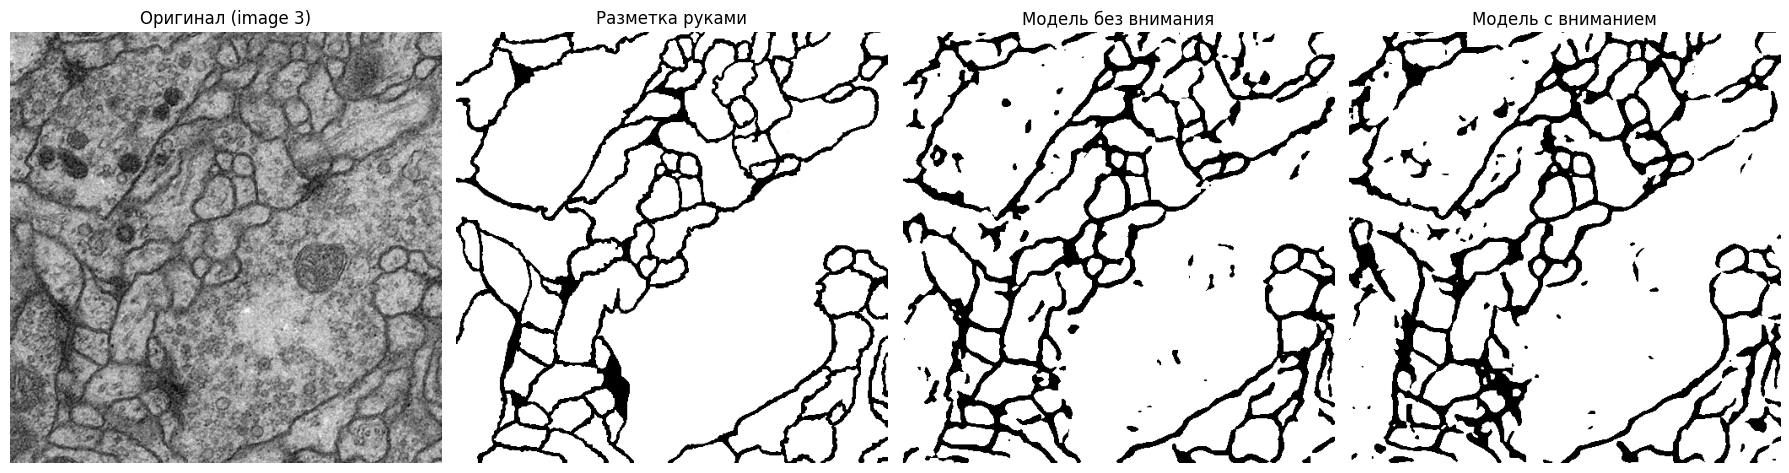

In [28]:
test_image_path = '/content/drive/MyDrive/Клеточные мембраны/test/image/3.png'
my_hand_mask_path = '/content/drive/MyDrive/Клеточные мембраны/test/mask/mask_3.png'

img = Image.open(test_image_path).convert('L')
hand_mask = Image.open(my_hand_mask_path).convert('L')

transform = T.Compose([
    T.Resize((512, 512)),
    T.ToTensor()
])

input_tensor = transform(img).unsqueeze(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
input_tensor = input_tensor.to(device)

with torch.no_grad():
  model_with_attention.eval()
  model_without_attention.eval()
  logits_with = model_with_attention(input_tensor)
  logits_without = model_without_attention(input_tensor)
  mask_with = (torch.sigmoid(logits_with) > 0.5).float().cpu().squeeze().numpy()
  mask_without = (torch.sigmoid(logits_without) > 0.5).float().cpu().squeeze().numpy()

plt.figure(figsize=(18, 10))

plt.subplot(1, 4, 1)
plt.imshow(img, cmap='gray')
plt.title("Оригинал (image 3)")
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(hand_mask, cmap='gray')
plt.title("Разметка руками")
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(mask_without, cmap='gray')
plt.title("Модель без внимания")
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(mask_with, cmap='gray')
plt.title("Модель с вниманием")
plt.axis('off')

plt.tight_layout()
plt.show()